<a href="https://colab.research.google.com/github/JuanDaAstronmy/MetodosComputacionales1012/blob/main/eleccion_de_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pyvo -q
import pyvo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time

tap = pyvo.dal.TAPService("https://archive.eso.org/tap_obs")

In [4]:
sistemas = {
    "LHS 1140": (11.248632, -15.274109)
}

In [5]:
def buscar_espectros(ra, dec, radio_arcmin=1.0):
    query = f"""
    SELECT target_name, dp_id, instrument_name, t_min, t_exptime,
           snr, obs_release_date, access_url
    FROM ivoa.ObsCore
    WHERE dataproduct_type = 'spectrum'
      AND CONTAINS(POINT('ICRS', s_ra, s_dec),
                   CIRCLE('ICRS', {ra}, {dec}, {radio_arcmin/60})) = 1
    """
    return tap.search(query, maxrec=20000).to_table().to_pandas()

In [6]:
tablas = []
for nombre, (ra, dec) in sistemas.items():
    df = buscar_espectros(ra, dec)
    df["sistema"] = nombre
    tablas.append(df)

espectros = pd.concat(tablas, ignore_index=True)
espectros["fecha"] = Time(espectros["t_min"], format="mjd").datetime
espectros["instrument_name"].value_counts()

,count
instrument_name,
HARPS,296
ESPRESSO,117
CRIRES,1


In [9]:
INSTR_LBL = ["HARPS", "ESPRESSO", "NIRPS"]
espectros_lbl = espectros[espectros["instrument_name"].isin(INSTR_LBL)].copy()

liberacion = pd.to_datetime(espectros_lbl["obs_release_date"], format="ISO8601", utc=True)
espectros_lbl["publico"] = liberacion <= pd.Timestamp.now(tz="UTC")

pd.crosstab([espectros_lbl["sistema"], espectros_lbl["publico"]],
            espectros_lbl["instrument_name"])

,instrument_name,ESPRESSO,HARPS
sistema,publico,,
LHS 1140,True,117,296


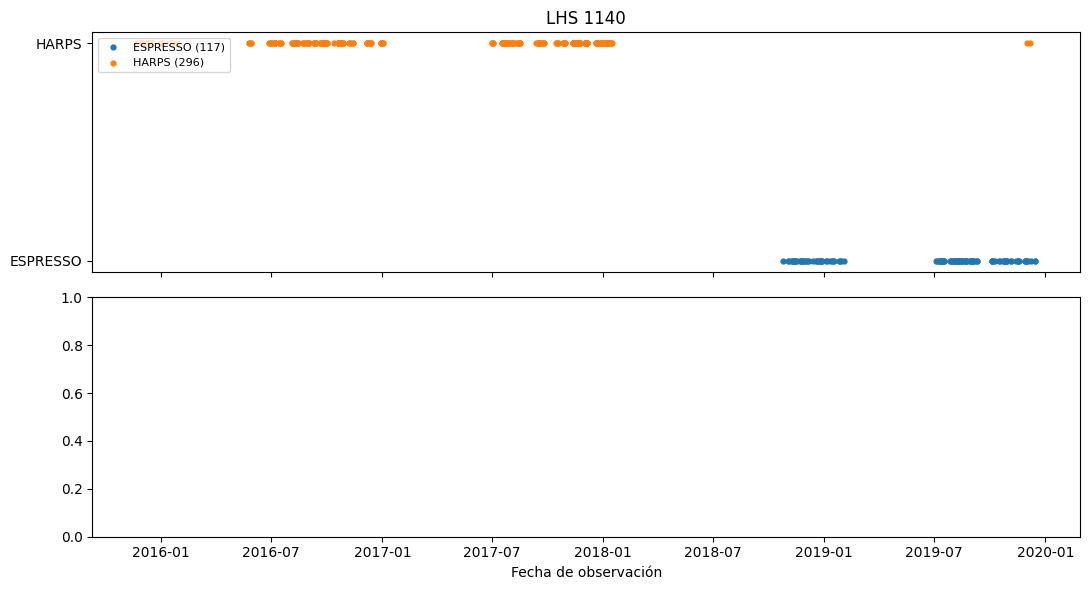

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

for ax, (nombre, grupo) in zip(axes, espectros_lbl.groupby("sistema")):
    for i, (inst, g) in enumerate(grupo.groupby("instrument_name")):
        ax.scatter(g["fecha"], np.full(len(g), i), s=12, label=f"{inst} ({len(g)})")
    ax.set_yticks(range(grupo["instrument_name"].nunique()))
    ax.set_yticklabels(sorted(grupo["instrument_name"].unique()))
    ax.set_title(nombre)
    ax.legend(loc="upper left", fontsize=8)

axes[-1].set_xlabel("Fecha de observación")
plt.tight_layout()